# Final six-model research comparison

Milestone 9 performs live analysis of saved results only. No training, inference or calibration is rerun. Licensed panel outputs remain local. The accompanying report supplies full interpretation and provenance.

## 1. Introduction and objectives

Compare detection, localization, frozen threshold transfer and measured cost without redefining historical policies. The recommendation is a research decision requiring new deployment validation.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd() if (Path.cwd()/'reports').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT/'src'))
from anomaly_detection.model_comparison import validate_coverage, category_macro, paired_statistics, MODELS, METRICS
D = ROOT/'reports/final_comparison'
runs = pd.read_csv(D/'all_runs.csv',float_precision='round_trip')
assert validate_coverage(runs)
print('Saved-artifact analysis only:',len(runs),'records; no model execution')


Saved-artifact analysis only: 270 records; no model execution


The analysis covers exactly 270 final evaluations without changing predictions. Research selection is conditional on this public benchmark and cannot substitute for a separate engineering validation dataset.

## 2. Methods and architectural variants

All six methods retain their recorded names and limitations; simplified PatchCore, SSN Lite and reduced EfficientAD are not paper-equivalent implementations.

In [2]:
display(runs[['model','score_direction','latency_scope']].drop_duplicates())

,model,score_direction,latency_scope
0,basic_cnn,higher_is_anomaly,memory-resident RGB -> native probability map ...
45,autoencoder,higher_is_anomaly,memory-resident RGB -> native residual map on ...
90,patchcore,higher_is_anomaly,Memory-resident decoded RGB -> native raw-dist...
135,supersimplenet,higher_is_anomaly,Decoded RGB -> native raw-logit CPU map + imag...
180,padim,higher_is_anomaly,Decoded RGB through native CPU map; file decod...
225,efficientad,higher_is_anomaly,decoded RGB to native CPU signed map; disk dec...


Pretrained methods share representations but use different adaptation, aggregation and smoothing. Reduced EfficientAD omits the external-image penalty and selects only the local map; its result cannot be attributed to the complete published architecture.

## 3. Dataset and shared partitions

The same fitting/development/calibration/test manifests supply all methods. Normal-only calibration and fixed category coverage are checked from saved identities.

In [3]:
display(pd.DataFrame(json.loads((D/'audit_summary.json').read_text())['partition_counts'].items(),columns=['partition','images']))

,partition,images
0,fit,2551
1,development,539
2,calibration,539
3,test,1725


The fitting/development/calibration/test counts are 2551/539/539/1725. Calibration contains only normal train images and has as few as nine samples per category, a central limitation for a nominal five-percent operating point.

## 4. Source and integrity audit

The deep audit hashes original run artifacts and reconciles 270 primary image evaluations from existing prediction CSVs. Pixel metrics remain the exact recorded native-resolution values.

In [4]:
display(json.loads((D/'audit_summary.json').read_text()))
display(pd.read_csv(D/'prediction_reconciliation.csv').groupby('model').agg(max_error=('max_metric_error','max'),all_flags_match=('prediction_flags_match','all')))

{'status': 'passed',
 'records': 270,
 'models': 6,
 'categories': 15,
 'seeds': [2026, 2027, 2028],
 'source_files': 3091,
 'source_bytes': 20369450420,
 'current_pass_seconds': 5.088871599989943,
 'hash_cache': 'Previously SHA256-verified unchanged size/mtime entries reused on recovery',
 'partition_counts': {'fit': 2551,
  'development': 539,
  'calibration': 539,
  'test': 1725},
 'prediction_max_metric_error': 0.0,
 'inference_or_training_executed': False,
 'method': 'source identities plus saved-prediction reconciliation; primary pixel metrics preserved'}

,max_error,all_flags_match
model,,
autoencoder,0,True
basic_cnn,0,True
efficientad,0,True
padim,0,True
patchcore,0,True
supersimplenet,0,True


All 270 primary image-metric comparisons have zero numerical error after the documented historical float32 restoration when needed. Large map/checkpoint identities are checked without recomputing predictions or native pixel metrics.

## 5. Canonical result construction

One row represents model/category/seed. Source result, prediction, configuration and calibration identities are retained; equal categories, not large image counts, determine macro values.

In [5]:
display(runs[['model','category','seed','source_result_sha256']].head(8))
assert not runs.duplicated(['model','category','seed']).any()

,model,category,seed,source_result_sha256
0,basic_cnn,bottle,2026,6c6c61ea6426b894a43fe2fa497800e6d28c595b8abd50...
1,basic_cnn,cable,2026,b73bb8497c238e66a23ec3d1e669d6b79a5300c1c314d9...
2,basic_cnn,capsule,2026,7719d499f23b14f7932e1e91ecfcc22ffdd23dba886107...
3,basic_cnn,carpet,2026,4aaf5ed845af3375a733fe6ffc50a424e855bbddd08890...
4,basic_cnn,grid,2026,2af245f61f654a9b60b80870116a514a9e397576ba1680...
5,basic_cnn,hazelnut,2026,28c5fef75d9e5fa4a11761bfc8070927e84baf0a4362ea...
6,basic_cnn,leather,2026,b6a127cd39f555b3f80cd6c9592ba6019d7cb4b9daa09c...
7,basic_cnn,metal_nut,2026,43bcdb64aa619f0c2ae984c1dc1aebbab3a6ce1b0d3b2c...


One row represents model/category/seed. Source result, prediction, configuration and calibration identities are retained; equal categories, not large image counts, determine macro values. Full quantitative values, scientific interpretation and practical limitations are retained in the accompanying written report and source-linked CSV tables.

## 6. Overall nine-metric comparison

Ranking and calibrated operating points are separate. A lower false-positive rate can coexist with very poor recall, so none of the nine metrics alone decides a candidate.

,image_auroc,image_ap,pixel_auroc,pixel_ap,au_pro,recall,fpr,precision,f1
model,,,,,,,,,
basic_cnn,0.712589,0.858954,0.785832,0.235382,0.549807,0.401760,0.098341,0.873299,0.510593
autoencoder,0.634623,0.827916,0.690002,0.110897,0.449350,0.235000,0.093944,0.789620,0.314635
patchcore,0.967572,0.988538,0.972944,0.540154,0.920399,0.890435,0.171806,0.940045,0.904345
supersimplenet,0.964783,0.986239,0.952850,0.436077,0.856502,0.892012,0.166249,0.941235,0.909892
padim,0.897933,0.946389,0.965920,0.453764,0.911929,0.696493,0.144521,0.925512,0.755358
efficientad,0.816298,0.918593,0.919887,0.498476,0.818373,0.665639,0.220081,0.885939,0.740084


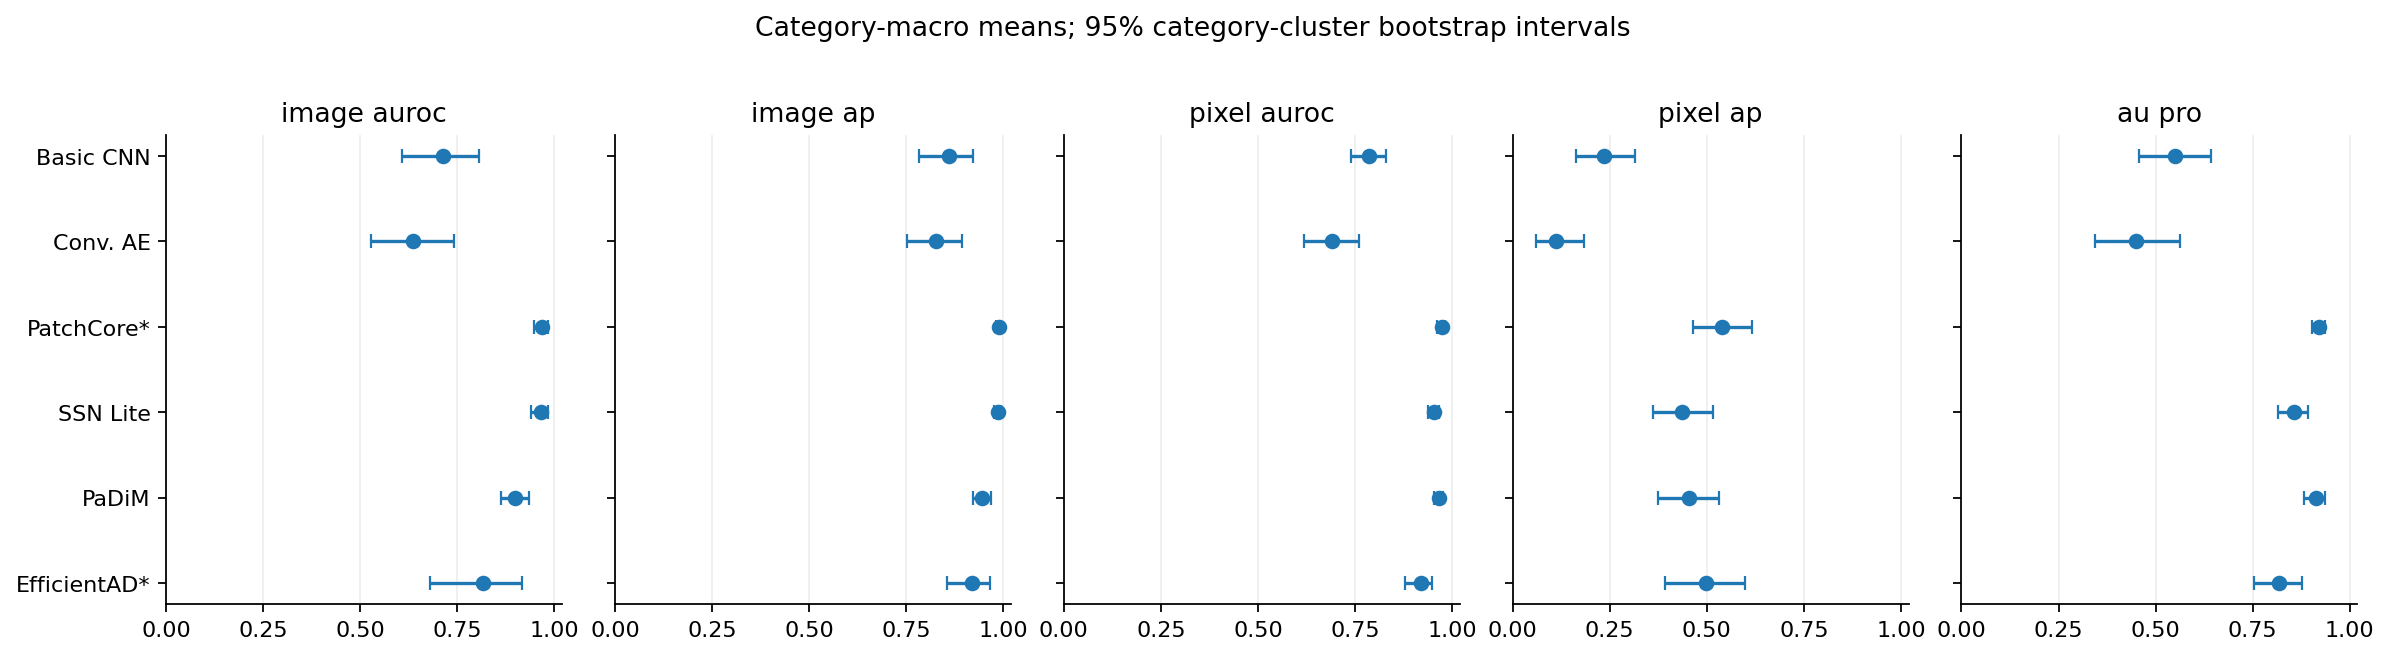

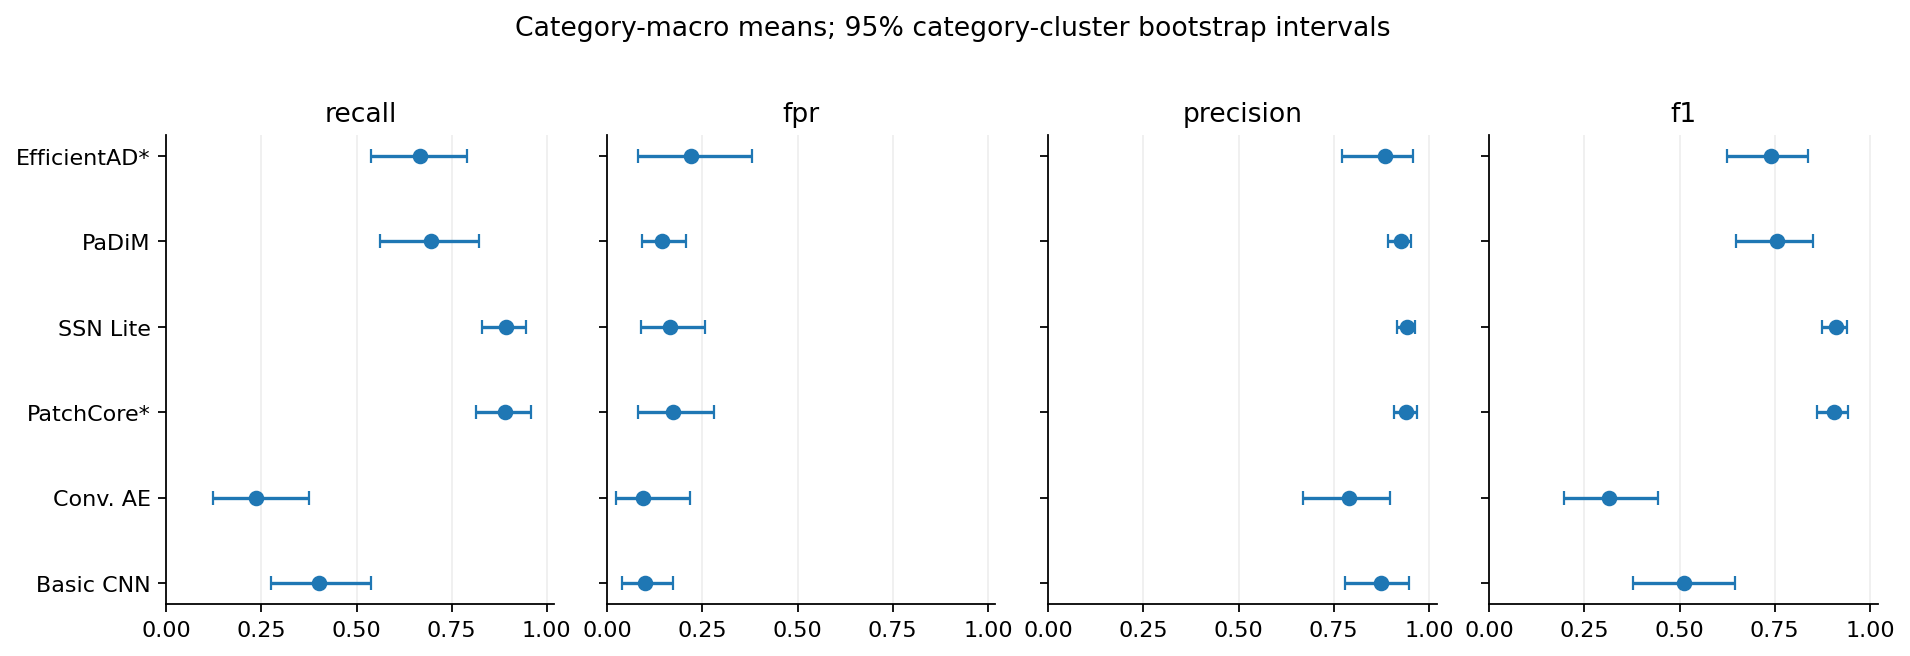

In [6]:
display(category_macro(runs).round(6))
display(Image(filename=str(D/'figures/ranking_metrics.png')))
display(Image(filename=str(D/'figures/operating_metrics.png')))

PatchCore has the highest ranking/localization macro point estimates; SSN Lite has slightly stronger frozen F1. The scratch methods achieve low FPR alongside low recall, demonstrating why false alarms must be read with missed defects.

## 7. Category image ranking

Every category has three paired seeds per architecture. Category heatmaps show descriptive rankings, not 15 independent declarations of superiority.

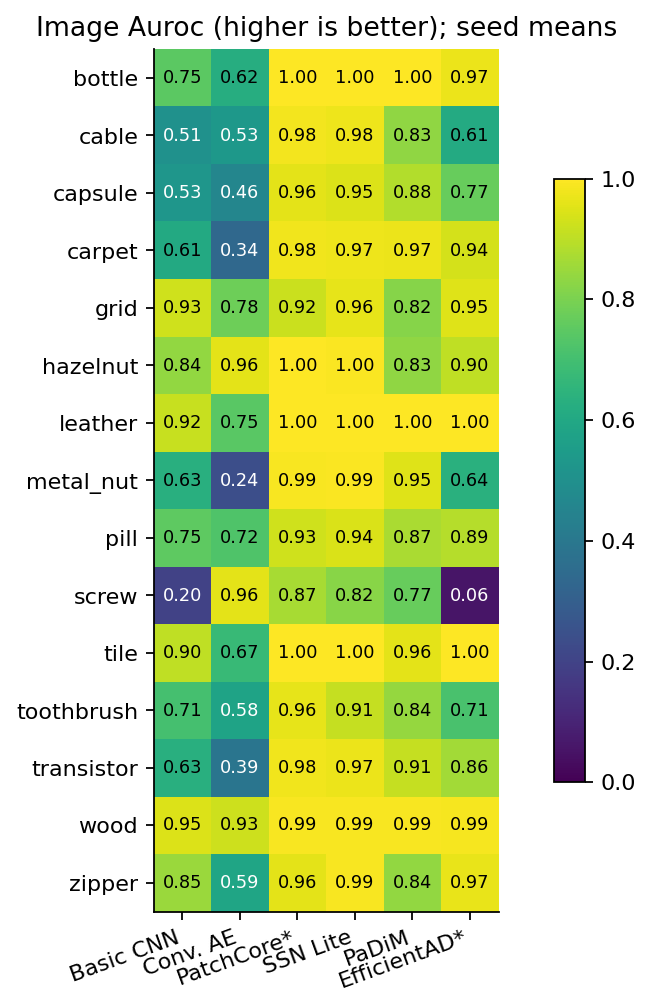

,category,image_leader,image_auroc,pixel_ap_leader,pixel_ap,image_auroc_range,efficientad_fpr
0,bottle,Simplified PatchCore,1.000000,Simplified PatchCore,0.729022,0.376720,0.000000
1,cable,Simplified PatchCore,0.982384,Simplified PatchCore,0.643408,0.476324,0.051724
2,capsule,Simplified PatchCore,0.958117,Simplified PatchCore,0.449028,0.497540,0.173913
3,carpet,Simplified PatchCore,0.977796,EfficientAD-S reduced-budget,0.653432,0.638309,0.583333
4,grid,SuperSimpleNet Lite,0.961571,EfficientAD-S reduced-budget,0.399841,0.181843,0.000000
5,hazelnut,Simplified PatchCore,0.999881,Simplified PatchCore,0.581337,0.165000,0.016667
6,leather,Simplified PatchCore,1.000000,EfficientAD-S reduced-budget,0.585680,0.254303,0.802083
7,metal_nut,SuperSimpleNet Lite,0.993809,Simplified PatchCore,0.850598,0.754969,0.424242
8,pill,SuperSimpleNet Lite,0.943262,Simplified PatchCore,0.711380,0.220404,0.038462
9,screw,Convolutional AE,0.957300,Simplified PatchCore,0.283067,0.900116,0.910569


In [7]:
display(Image(filename=str(D/'figures/heatmap_image_auroc.png')))
display(pd.read_csv(D/'category_findings.csv'))

Screw changes rankings substantially: AE image AUROC is 0.9573, PatchCore 0.8690, SSN Lite 0.8226, PaDiM 0.7662 and reduced EfficientAD 0.0572. AE nevertheless has screw recall only 0.0644 at its frozen cutoff.

## 8. Category localization

Pixel AP penalizes diffuse or off-target responses differently from pixel AUROC. AU-PRO weights connected defect regions rather than treating each pixel as an independent replicate.

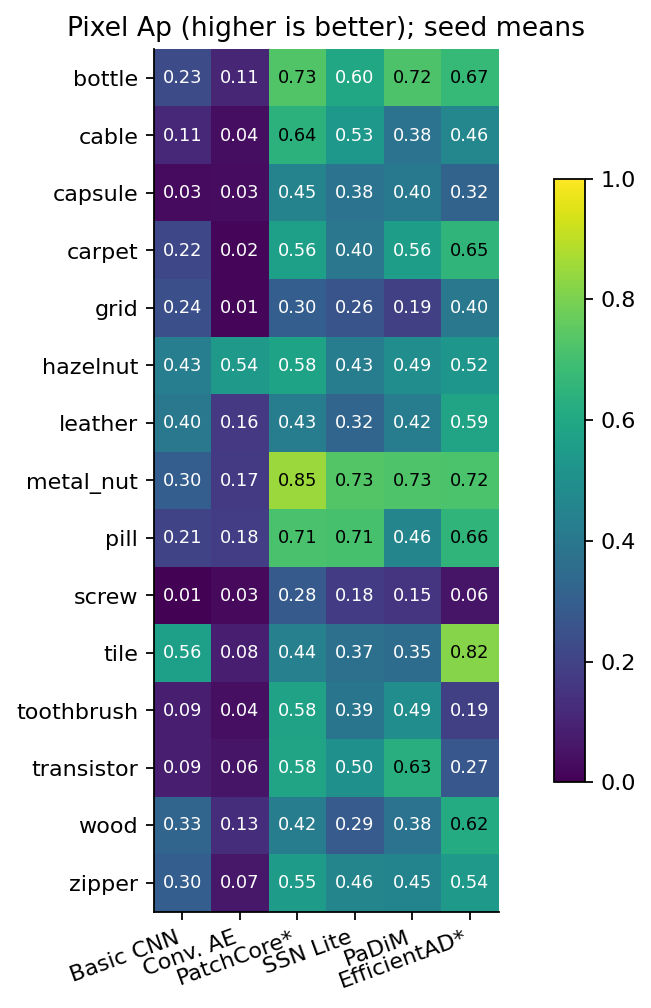

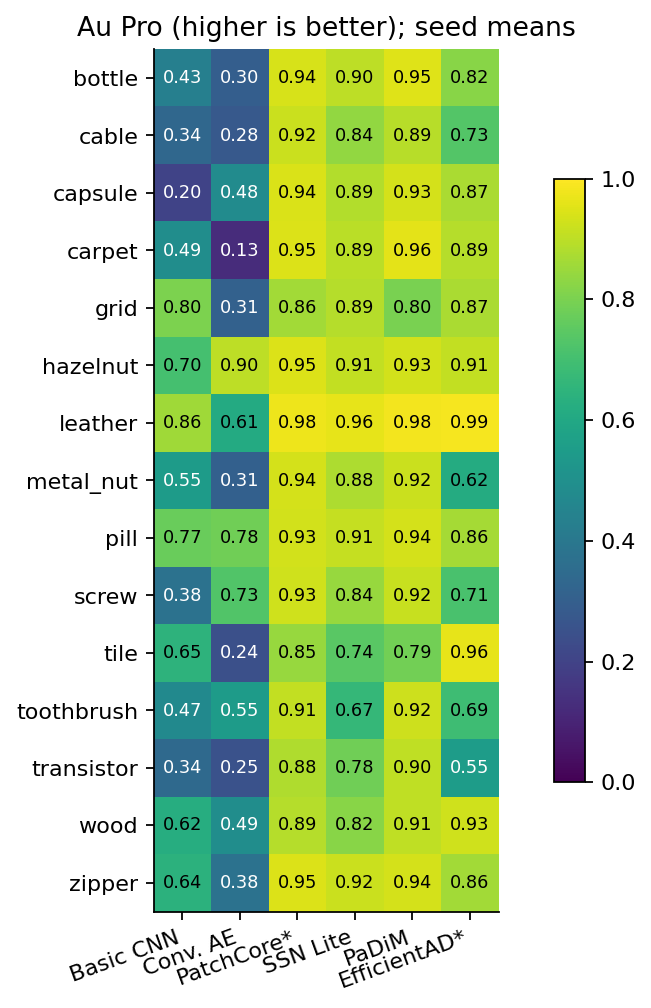

In [8]:
display(Image(filename=str(D/'figures/heatmap_pixel_ap.png')))
display(Image(filename=str(D/'figures/heatmap_au_pro.png')))

PatchCore macro pixel AP is 0.5402 versus SSN Lite 0.4361 and PaDiM 0.4538. Reduced EfficientAD reaches 0.4985 despite weaker image ranking; AE screw pixel AP is only 0.0263 despite strong image ranking.

## 9. Objects, textures and seed instability

Five textures and ten objects are summarized separately. Three seeds share official test images; their variation measures experimental factors, not three independent test datasets.

,model,kind,image_auroc,image_ap,pixel_auroc,pixel_ap,au_pro,recall,fpr,precision,f1
0,autoencoder,object,0.6056,0.8053,0.7333,0.1256,0.4952,0.2092,0.0498,0.8258,0.3075
1,autoencoder,texture,0.6926,0.8732,0.6035,0.0815,0.3576,0.2865,0.1821,0.7173,0.3289
2,basic_cnn,object,0.6388,0.8150,0.7707,0.1779,0.4831,0.2676,0.0823,0.8441,0.3835
3,basic_cnn,texture,0.8602,0.9468,0.8162,0.3504,0.6833,0.6701,0.1304,0.9318,0.7647
4,efficientad,object,0.7377,0.8820,0.8955,0.4404,0.7637,0.5744,0.1828,0.8697,0.6781
5,efficientad,texture,0.9735,0.9918,0.9686,0.6146,0.9276,0.8481,0.2946,0.9185,0.8640
6,padim,object,0.8732,0.9297,0.9746,0.4904,0.9245,0.6304,0.1739,0.9060,0.6935
7,padim,texture,0.9474,0.9797,0.9487,0.3806,0.8868,0.8287,0.0858,0.9646,0.8791
8,patchcore,object,0.9629,0.9866,0.9781,0.5957,0.9286,0.8668,0.0956,0.9574,0.8984
9,patchcore,texture,0.9769,0.9924,0.9627,0.4290,0.9040,0.9377,0.3242,0.9054,0.9161


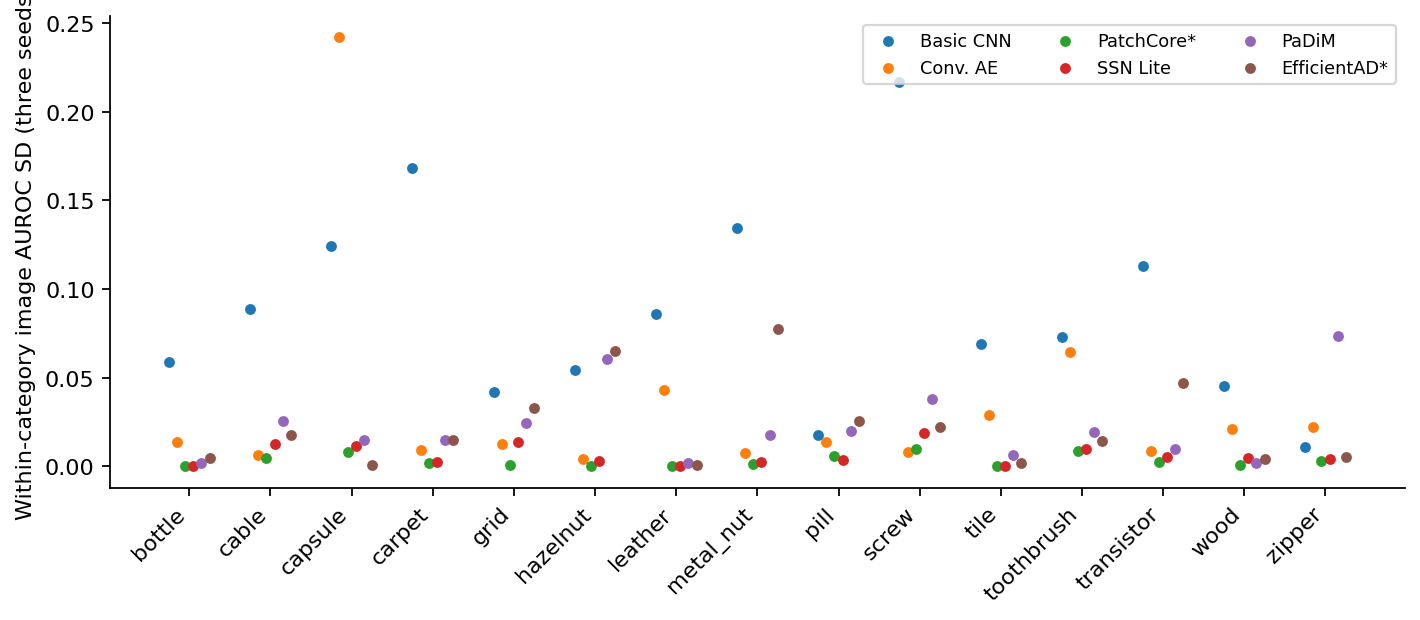

In [9]:
display(pd.read_csv(D/'texture_object_summary.csv').round(4))
display(Image(filename=str(D/'figures/seed_stability.png')))

These summaries retain each model/category seed SD rather than treating seeds as independent datasets. Texture failures are strongly category dependent: leather can rank nearly perfectly while transferring its cutoff poorly.

## 10. Paired statistical uncertainty

Resample 15 paired category means after averaging seeds. Exact sign randomization assumes category exchangeability; Holm adjustment spans all 135 contrasts. No pixel-level independence is assumed.

In [10]:
computed = paired_statistics(runs)
stored = pd.read_csv(D/'paired_comparisons.csv',float_precision='round_trip')
import numpy as np
assert np.allclose(computed.difference,stored.difference,atol=1e-14)
display(stored.query("model_a == 'patchcore' and model_b == 'supersimplenet'")[['metric','difference','ci_low','ci_high','p_holm_135']])
print('Holm p<.05 contrasts:',int((stored.p_holm_135<.05).sum()),'of',len(stored))

,metric,difference,ci_low,ci_high,p_holm_135
81,image_auroc,0.002789,-0.008712,0.014768,1.000000
82,image_ap,0.002299,-0.002343,0.007051,1.000000
83,pixel_auroc,0.020094,0.011166,0.029024,0.064941
84,pixel_ap,0.104077,0.079480,0.127655,0.008240
85,au_pro,0.063897,0.038051,0.095704,0.021729
86,recall,-0.001577,-0.041871,0.038458,1.000000
87,fpr,0.005557,-0.034981,0.045602,1.000000
88,precision,-0.001190,-0.016199,0.014159,1.000000
89,f1,-0.005547,-0.028099,0.014485,1.000000


Holm p<.05 contrasts: 56 of 135


The complete paired table retains all effects and uncertainty, including null results. Small PatchCore/SSN image-ranking differences do not establish superiority. Category-bootstrap intervals and multiplicity-adjusted tests address different uncertainty questions.

## 11. Calibration sample size and ties

Nominal .05 is a quantile policy, not a guaranteed test FPR. Small calibration sets and strict ties make achieved calibration exceedance rates discrete and often below nominal.

,model,calibration_n,calibration_fpr,fpr,recall,precision,f1,runs_with_threshold_ties
0,autoencoder,35.93333,0.02952,0.09394,0.23500,0.78962,0.31464,0
1,basic_cnn,35.93333,0.02952,0.09834,0.40176,0.87330,0.51059,0
2,efficientad,35.93333,0.02737,0.22008,0.66564,0.88594,0.74008,3
3,padim,35.93333,0.02952,0.14452,0.69649,0.92551,0.75536,0
4,patchcore,35.93333,0.02952,0.17181,0.89043,0.94004,0.90434,0
5,supersimplenet,35.93333,0.02952,0.16625,0.89201,0.94123,0.90989,0


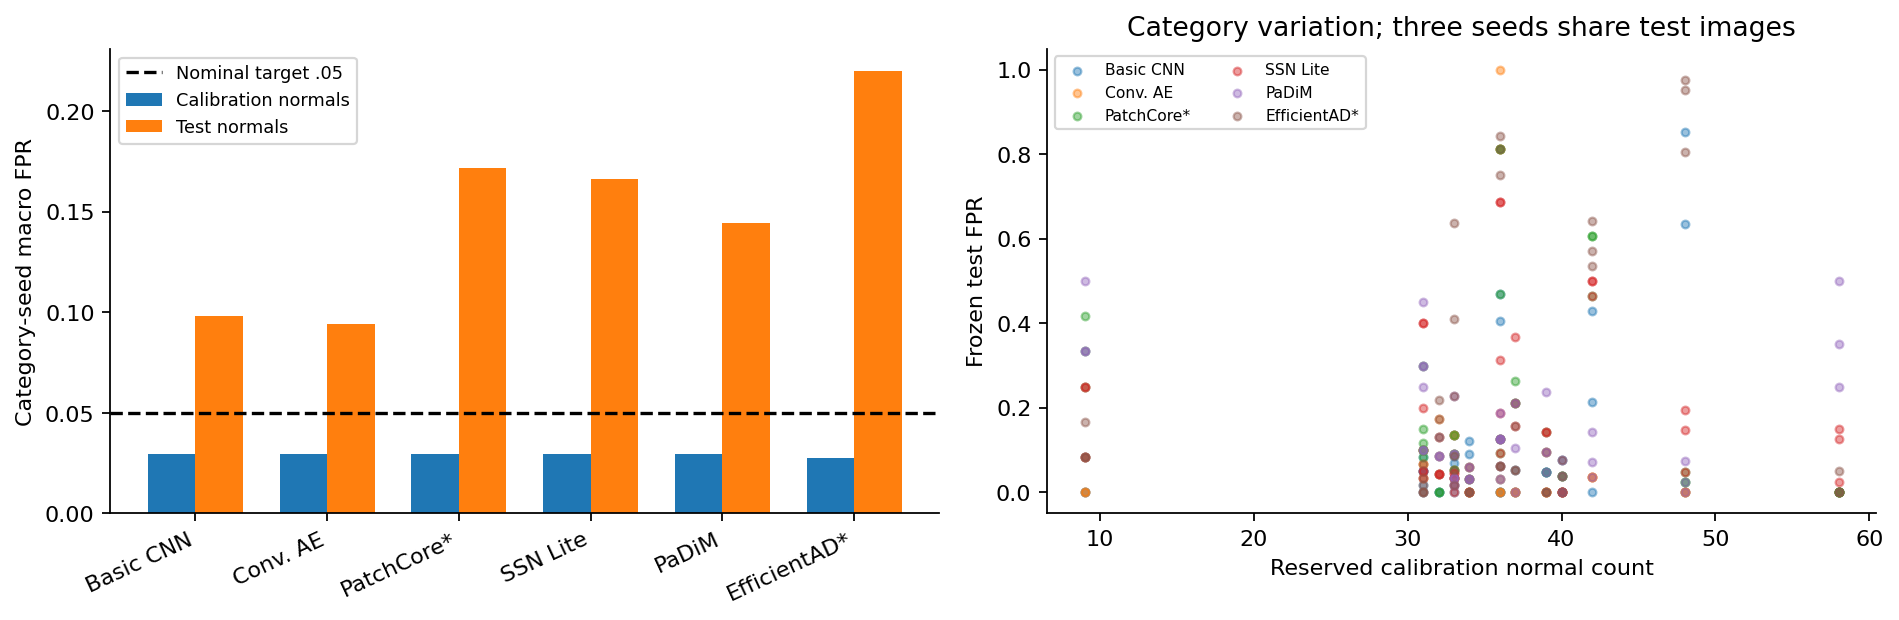

In [11]:
display(pd.read_csv(D/'calibration_summary.csv').round(5))
display(Image(filename=str(D/'figures/calibration_transfer.png')))

Calibration exceedance is measured on the same normals that set the cutoff and is not a future-risk guarantee. EfficientAD exhibits a large calibration-to-test FPR gap; ties and genuine texture hot spots are recorded evidence, while distribution shift remains a possible explanation.

## 12. Threshold transfer by category

Compare recall and FPR at the frozen cutoff only. Test normal binomial intervals condition on an existing model; repeated-seed intervals are not pooled as independent observations.

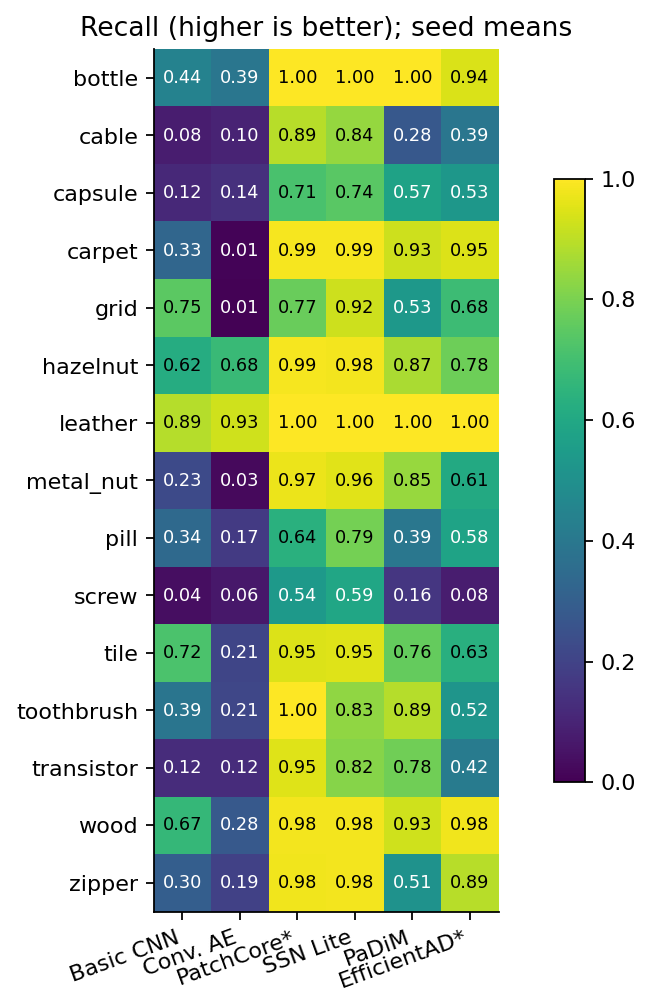

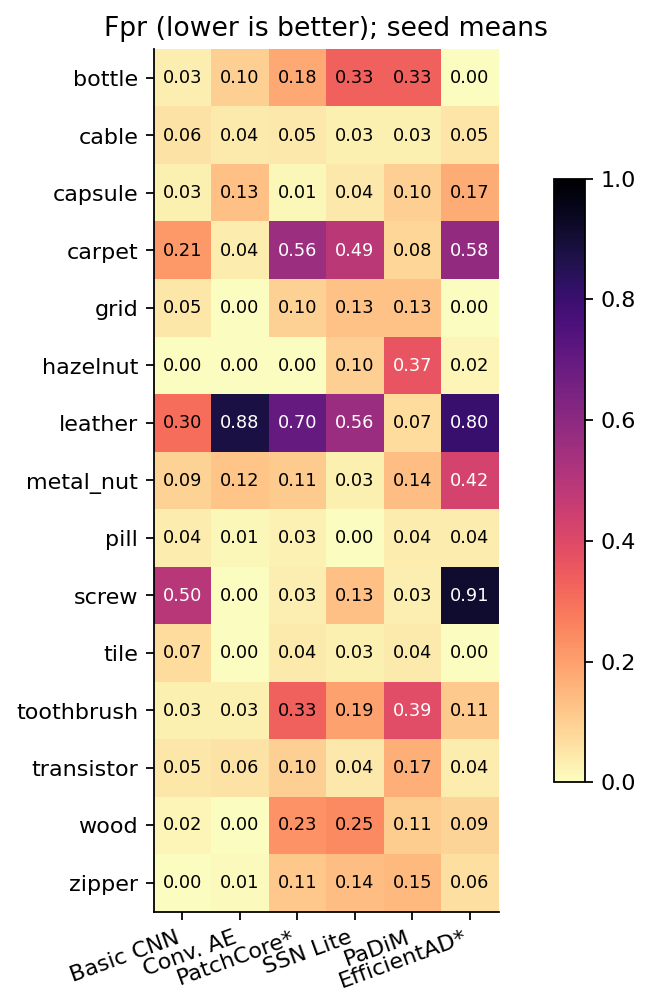

,model,category,min,mean,max,std,relative_range
0,autoencoder,bottle,0.062488,0.078576,0.089260,0.014181,0.340716
1,autoencoder,cable,0.186563,0.193551,0.203304,0.008707,0.086495
2,autoencoder,capsule,0.018889,0.067724,0.164687,0.083973,2.152816
3,autoencoder,carpet,0.089184,0.089439,0.089857,0.000365,0.007525
4,autoencoder,grid,0.064338,0.066276,0.068300,0.001982,0.059780
5,autoencoder,hazelnut,0.014772,0.015407,0.015737,0.000550,0.062639
6,autoencoder,leather,0.008297,0.010056,0.012400,0.002113,0.407970
7,autoencoder,metal_nut,0.061602,0.069494,0.080920,0.010133,0.277983
8,autoencoder,pill,0.025495,0.028086,0.030932,0.002727,0.193572
9,autoencoder,screw,0.028561,0.034248,0.038702,0.005182,0.296101


In [12]:
display(Image(filename=str(D/'figures/heatmap_recall.png')))
display(Image(filename=str(D/'figures/heatmap_fpr.png')))
display(pd.read_csv(D/'threshold_seed_variability.csv').head(15))

PatchCore leather/carpet FPR is 0.6979/0.5595; SSN Lite is 0.5625/0.4881. Reduced EfficientAD is 0.8021/0.5833. These actual rates prevent a claim that the frozen threshold transfers reliably even for the strongest ranking models.

## 13. Compute and storage

Latencies are medians of per-run percentiles, not a pooled percentile. Decoded-RGB end-to-end timings exclude file decode. Missing early RSS remains missing; metric-sort peaks are not serving minima.

,model,training_seconds,evaluation_seconds,model_p50_ms,model_p95_ms,end_to_end_p50_ms,end_to_end_p95_ms,checkpoint_bytes,train_peak_vram_gib,inference_peak_vram_gib,cpu_peak_rss_gib,training_hours,evaluation_hours,category_checkpoint_mib,shared_trunk_mib,deployment_mib_one_category
0,autoencoder,1359.6900,3522.1354,3.3273,5.1242,14.0110,16.4359,131133,0.6072,0.0370,NaN,0.3777,0.9784,0.1251,0.000,0.1251
1,basic_cnn,486.6253,2123.1120,2.4298,3.8787,10.3426,13.3640,343117,0.4805,0.0441,NaN,0.1352,0.5898,0.3272,0.000,0.3272
2,efficientad,8575.5513,2814.0643,21.9824,26.4717,30.5405,35.0719,32249772,0.3089,0.1072,5.8039,2.3821,0.7817,30.7558,0.000,30.7558
3,padim,35.8062,1779.2243,12.8722,16.1123,20.8881,24.7457,165480613,0.3839,0.2315,7.0004,0.0099,0.4942,157.8146,10.662,168.4766
4,patchcore,118.9136,4092.5829,15.2991,17.1336,33.9325,37.2452,3198733,1.1494,0.0784,5.7659,0.0330,1.1368,3.0505,10.662,13.7126
5,supersimplenet,5348.8888,2697.5955,9.6683,17.0836,28.6551,39.2048,2230175,0.7092,0.0819,5.5177,1.4858,0.7493,2.1269,10.662,12.7889


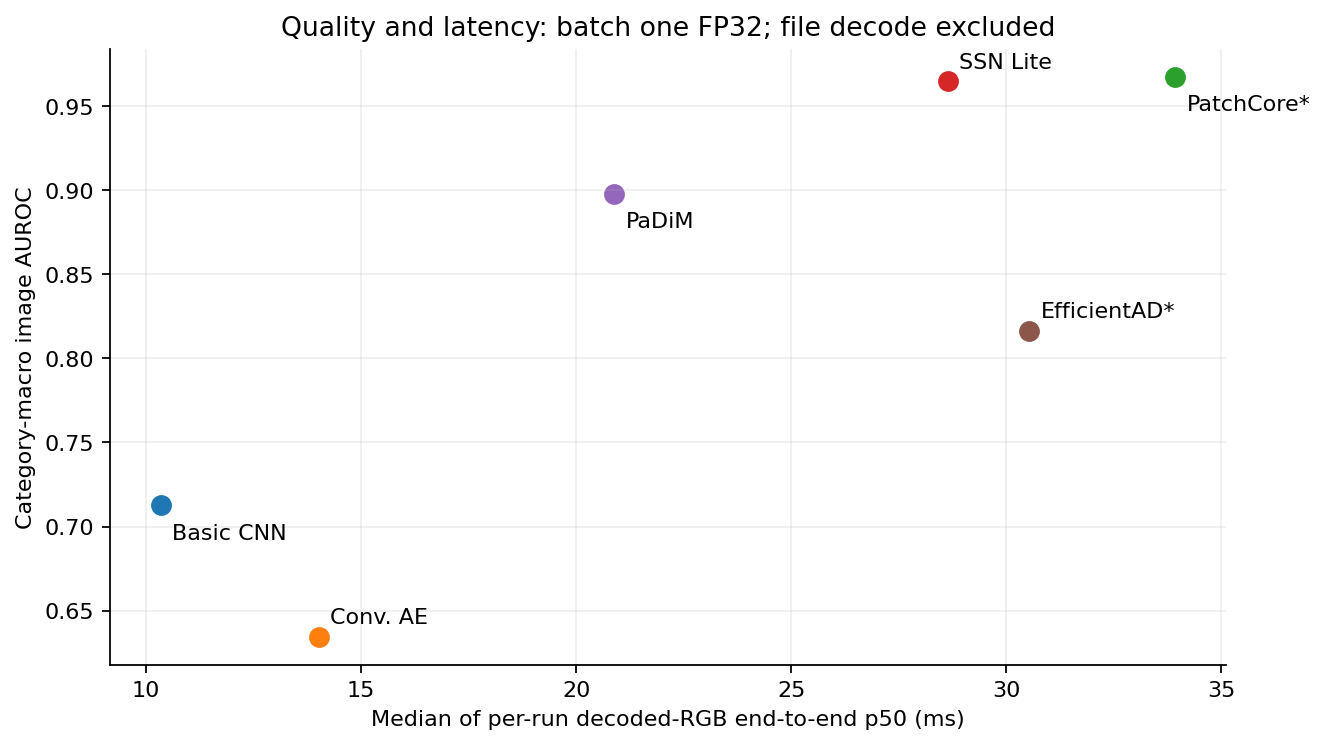

In [13]:
display(pd.read_csv(D/'compute_summary.csv').round(4))
display(Image(filename=str(D/'figures/quality_latency.png')))

Using medians of per-run decoded-RGB end-to-end p50, PatchCore takes 33.93 ms, SSN Lite 28.66 ms, PaDiM 20.89 ms and EfficientAD 30.54 ms. These exclude file decoding; training times omit shared pretraining and differ in feature-cache reuse.

## 14. Failure evidence and existing examples

Existing failure tables and original notebooks are the evidence. Inspect all 15 saved EfficientAD panels locally; no model rerun or new predictions are produced. Public outputs clear licensed dataset pixels.

In [14]:
display(pd.read_csv(D/'failure_source_inventory.csv'))
panels=pd.read_csv(ROOT/'reports/efficientad/failure_examples.csv').groupby('category',sort=True).first()
for category,row in panels.iterrows():
    print(category,row['outcome'],row['path'])
    panel=ROOT/row['panel']
    if panel.exists():
        display(Image(filename=str(panel),width=1050))
    else:
        print('Licensed local panel unavailable; source identity retained')
for evidence in json.loads((D/'visual_evidence_provenance.json').read_text()):
    panel=ROOT/evidence['path']
    print(evidence['path'])
    if panel.exists():
        display(Image(filename=str(panel),width=1000))

These are genuine previously saved examples, not newly inferred maps. Screw scratch responses can coexist with image misses; normal leather shows actual hot spots, and grid responses extend beyond the annotated thread. See the original visual-review document for all 15 recorded observations.

## 15. Fine defects, halos and aggregation

The original size summaries have different seed scopes. Preserve each source, and distinguish observed misses/spatial spread from hypothesized bank-coverage, Gaussian-alignment or synthetic-transfer mechanisms.

In [15]:
for model in MODELS:
    p=ROOT/'reports'/model/'small_defect_summary.csv'
    if p.exists():
        print(model,'original saved size-summary scope')
        display(pd.read_csv(p))

autoencoder original saved size-summary scope


,size_group,images,recall,median_mask_fraction
0,at most 0.1%,17,0.235294,0.000861
1,0.1% to 1%,482,0.257261,0.004050
2,above 1%,759,0.241107,0.031327


patchcore original saved size-summary scope


,size_group,images,recall,median_mask_fraction
0,at most 0.1%,17,0.647059,0.000861
1,0.1% to 1%,482,0.751037,0.004050
2,above 1%,759,0.938076,0.031327


supersimplenet original saved size-summary scope


,size_group,images,recall,median_mask_fraction
0,at most 0.1%,17,0.764706,0.000861
1,0.1% to 1%,482,0.778008,0.004050
2,above 1%,759,0.942029,0.031327


padim original saved size-summary scope


,size_stratum,images_across_seeds,detected,mean_score,recall
0,<=0.1%,51,32,18.547859,0.627451
1,0.1-1%,1446,788,18.543502,0.544952
2,1-5%,1548,1051,19.815235,0.678941
3,>5%,729,553,21.180213,0.758573


efficientad original saved size-summary scope


,category,size_bin,images,recall,mean_defect_fraction,images_with_pixel_overlap
0,bottle,small_le_1pct,9,1.000000,0.007102,9
1,bottle,larger,180,0.938889,0.079619,180
2,cable,small_le_1pct,21,0.238095,0.006391,16
3,cable,larger,255,0.403922,0.050140,227
4,capsule,tiny_le_0.1pct,21,0.666667,0.000767,18
5,capsule,small_le_1pct,234,0.500000,0.003919,227
6,capsule,larger,72,0.583333,0.037401,72
7,carpet,small_le_1pct,111,0.945946,0.004877,111
8,carpet,larger,156,0.948718,0.032583,156
9,grid,small_le_1pct,117,0.726496,0.004969,114


The original size summaries have different seed scopes. Preserve each source, and distinguish observed misses/spatial spread from hypothesized bank-coverage, Gaussian-alignment or synthetic-transfer mechanisms. Full quantitative values, scientific interpretation and practical limitations are retained in the accompanying written report and source-linked CSV tables.

## 16. Multicriteria research selection

Shortlist PatchCore and SSN Lite by macro image AUROC, then consider localization, frozen FPR/recall, latency, storage and provenance transparently. No arbitrary weighted total is constructed.

In [16]:
shortlist=category_macro(runs).sort_values('image_auroc',ascending=False).head(2)
display(shortlist)
print('Quality-first research prototype: Simplified PatchCore; faster balanced alternative: SSN Lite')

,image_auroc,image_ap,pixel_auroc,pixel_ap,au_pro,recall,fpr,precision,f1
model,,,,,,,,,
patchcore,0.967572,0.988538,0.972944,0.540154,0.920399,0.890435,0.171806,0.940045,0.904345
supersimplenet,0.964783,0.986239,0.952850,0.436077,0.856502,0.892012,0.166249,0.941235,0.909892


Quality-first research prototype: Simplified PatchCore; faster balanced alternative: SSN Lite


Shortlist PatchCore and SSN Lite by macro image AUROC, then consider localization, frozen FPR/recall, latency, storage and provenance transparently. No arbitrary weighted total is constructed. Full quantitative values, scientific interpretation and practical limitations are retained in the accompanying written report and source-linked CSV tables.

## 17. Engineering recommendation and provenance

The selected research candidate is not a production-cleared model. Resolve weight/data rights, validate new acquisition conditions and calibrate a justified deployment policy on independent normal data in a later phase.

In [17]:
display(Markdown('PatchCore for quality-first prototyping; SSN Lite for latency/quality balance; PaDiM for low measured fitting cost. No engineering application is started.'))

PatchCore for quality-first prototyping; SSN Lite for latency/quality balance; PaDiM for low measured fitting cost. No engineering application is started.

The selected research candidate is not a production-cleared model. Resolve weight/data rights, validate new acquisition conditions and calibrate a justified deployment policy on independent normal data in a later phase. Full quantitative values, scientific interpretation and practical limitations are retained in the accompanying written report and source-linked CSV tables.

## 18. Research limitations

One dataset, three dependent seeds, unequal architectures/budgets, missing early RSS, cached fitting and historical GPU power variation limit comparisons. Pretraining associations are observational, not causal ablations.

In [18]:
display(Markdown('Full limitations and observed-versus-hypothesized failure interpretations: [written report](../reports/final_comparison/report.md).'))

Full limitations and observed-versus-hypothesized failure interpretations: [written report](../reports/final_comparison/report.md).

One dataset, three dependent seeds, unequal architectures/budgets, missing early RSS, cached fitting and historical GPU power variation limit comparisons. Pretraining associations are observational, not causal ablations. Full quantitative values, scientific interpretation and practical limitations are retained in the accompanying written report and source-linked CSV tables.

## 19. Final conclusions

Pretrained feature methods are strongest descriptively here. Reduced EfficientAD has substantial threshold-transfer problems despite useful pixel responses. None of these results establishes universal industrial performance.

In [19]:
display(category_macro(runs)[['image_auroc','pixel_ap','recall','fpr','f1']].round(4))

,image_auroc,pixel_ap,recall,fpr,f1
model,,,,,
basic_cnn,0.7126,0.2354,0.4018,0.0983,0.5106
autoencoder,0.6346,0.1109,0.2350,0.0939,0.3146
patchcore,0.9676,0.5402,0.8904,0.1718,0.9043
supersimplenet,0.9648,0.4361,0.8920,0.1662,0.9099
padim,0.8979,0.4538,0.6965,0.1445,0.7554
efficientad,0.8163,0.4985,0.6656,0.2201,0.7401


Pretrained feature methods are strongest descriptively here. Reduced EfficientAD has substantial threshold-transfer problems despite useful pixel responses. None of these results establishes universal industrial performance. Full quantitative values, scientific interpretation and practical limitations are retained in the accompanying written report and source-linked CSV tables.

## 20. References and reproducibility

All primary experimental claims come from pinned local records, not paper tables. Rebuild canonical analysis with the project interpreter; deep auditing also requires excluded local weights/maps. Read the report for exact commands and primary references.

In [20]:
display(Markdown('See [research report and references](../reports/final_comparison/report.md), [analysis plan](../reports/final_comparison/analysis_plan.md), and [source provenance](../reports/final_comparison/source_provenance.json).'))

See [research report and references](../reports/final_comparison/report.md), [analysis plan](../reports/final_comparison/analysis_plan.md), and [source provenance](../reports/final_comparison/source_provenance.json).

All primary experimental claims come from pinned local records, not paper tables. Rebuild canonical analysis with the project interpreter; deep auditing also requires excluded local weights/maps. Read the report for exact commands and primary references. Full quantitative values, scientific interpretation and practical limitations are retained in the accompanying written report and source-linked CSV tables.